# Poisson Regression

Hourly arrivals are counts, and their variability grows with their expected value. A Poisson regression fits a positive mean with a log link.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Machine Learning collection.")

## Simulate arrivals

The original simulation has a daily cycle and a weekend effect. Each observation covers exactly one hour.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import PoissonRegressor
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score,
    mean_poisson_deviance,
)
from scipy.stats import poisson


def arrivals(days=105):
    rng = np.random.default_rng(17)
    hours = np.arange(days * 24)
    angle = 2 * np.pi * (hours % 24) / 24
    weekend = (hours // 24 % 7 >= 5).astype(float)
    X = np.column_stack([np.sin(angle), np.cos(angle), weekend])
    rate = np.exp(2.4 + 0.65 * X[:, 0] - 0.35 * X[:, 1] - 0.28 * weekend)
    return X, rng.poisson(rate), rate

## Forecast later days

The first 75 days are used to fit. Predictions for the next 30 days are compared with a constant training-mean forecast.

Poisson GLM: Poisson deviance 0.986 | MAE 2.616 | RMSE 3.379 | R² 0.754
Training mean: Poisson deviance 4.009 | MAE 5.741 | RMSE 6.816 | R² -0.000
Nominal 90% prediction interval coverage 0.935 | mean width 10.68 counts


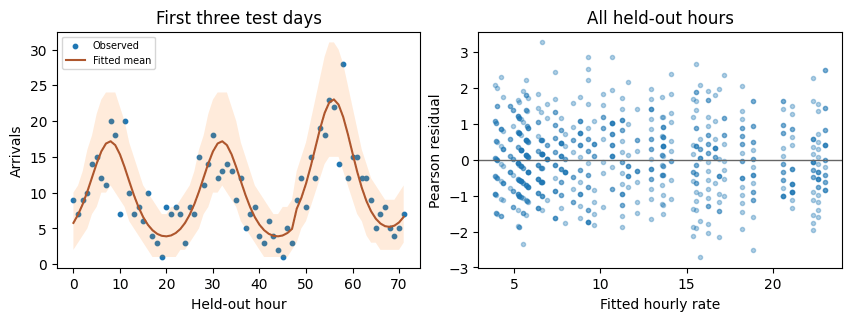

In [3]:
X, y, rate = arrivals()
split = 75 * 24
truth = y[split:]
model = PoissonRegressor(alpha=0.001, max_iter=250).fit(X[:split], y[:split])
pred = model.predict(X[split:])
for label, p in [("Poisson GLM", pred), ("Training mean", np.full(len(truth), y[:split].mean()))]:
    print(
        f"{label}: Poisson deviance {mean_poisson_deviance(truth,p):.3f} | MAE {mean_absolute_error(truth,p):.3f} | RMSE {root_mean_squared_error(truth,p):.3f} | R² {r2_score(truth,p):.3f}"
    )
lo, hi = poisson.interval(0.90, pred)
print(
    f"Nominal 90% prediction interval coverage {np.mean((truth>=lo)&(truth<=hi)):.3f} | mean width {(hi-lo).mean():.2f} counts"
)
fig, (a, b) = plt.subplots(1, 2, figsize=(8.4, 3.1), constrained_layout=True)
t = np.arange(72)
a.scatter(t, truth[:72], s=10, label="Observed")
a.plot(t, pred[:72], color="#ae562d", label="Fitted mean")
a.fill_between(t, lo[:72], hi[:72], alpha=0.15)
a.set(xlabel="Held-out hour", ylabel="Arrivals", title="First three test days")
a.legend(fontsize=7)
b.scatter(pred, (truth - pred) / np.sqrt(pred), s=9, alpha=0.35)
b.axhline(0, color="0.4", lw=1)
b.set(xlabel="Fitted hourly rate", ylabel="Pearson residual", title="All held-out hours")
plt.show()

## Reading the result

The predictive interval uses Poisson sampling variation conditional on the fitted mean. The known generating process makes this a check of the model under its assumptions.

## References

[scikit-learn, PoissonRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.PoissonRegressor.html)

[SciPy, Poisson distribution](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.poisson.html)